# Install torchcam

In [2]:
!pip install torchcam --no-deps -q
print("TorchCAM installed")

TorchCAM installed


# Imports + Paths + Constants

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchcam.methods import GradCAM
from torchcam.utils import overlay_mask
from PIL import Image
import matplotlib.pyplot as plt
import os
import shutil
from sklearn.model_selection import train_test_split

# Dataset path (your Kaggle dataset)
DATASET_ROOT = "/kaggle/input/datasets/christophernisshan/woman-body-shape-522"

# Classes — make sure these exactly match the subfolder names inside your dataset!
body_shapes = ['apple', 'hourglass', 'inverted_triangle', 'pear', 'rectangle']
NUM_CLASSES = len(body_shapes)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


# Data Transforms + Loaders

In [5]:
train_transform = transforms.Compose([
    transforms.Resize(299),
    transforms.RandomResizedCrop(299, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize(299),
    transforms.CenterCrop(299),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Directories
train_dir = os.path.join(DATASET_ROOT, 'train')
valid_dir = os.path.join(DATASET_ROOT, 'valid')
test_dir  = os.path.join(DATASET_ROOT, 'test')   # we can use it later for final eval

train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
valid_dataset = datasets.ImageFolder(valid_dir, transform=val_test_transform)
# test_dataset  = datasets.ImageFolder(test_dir, transform=val_test_transform)   # optional

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print(f"\nTrain samples: {len(train_dataset)}")
print(f"Valid samples: {len(valid_dataset)}")
# print(f"Test samples:  {len(test_dataset)}")   # uncomment if you want

print("Detected classes:", train_dataset.classes)


Train samples: 1092
Valid samples: 105
Detected classes: ['apple', 'hourglass', 'inverted_triangle', 'pear', 'rectangle']


# Model + Training Loop

In [6]:
model = models.inception_v3(weights='DEFAULT')
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=4)

best_val_acc = 0.0
num_epochs = 60

for epoch in range(num_epochs):
    # Training phase
    model.train()
    train_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        # Handle auxiliary logit during training
        if isinstance(outputs, tuple):
            loss = criterion(outputs[0], labels) + 0.4 * criterion(outputs[1], labels)
        else:
            loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * inputs.size(0)
    
    train_loss /= len(train_dataset)

    # Validation phase
    model.eval()
    val_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in valid_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            outputs = outputs[0] if isinstance(outputs, tuple) else outputs
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    
    val_loss /= total
    val_acc = 100.0 * correct / total

    print(f"Epoch {epoch+1:2d}/{num_epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")
    print(f"   Current LR: {optimizer.param_groups[0]['lr']:.6f}")

    scheduler.step(val_loss)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "/kaggle/working/best_body_shape_model.pth")
        print(f"→ New best model saved (Val Acc: {val_acc:.2f}%)")

print("\nTraining complete!")
print("Best model → /kaggle/working/best_body_shape_model.pth")
print("Download it from the Output files sidebar.")

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 180MB/s]  


Epoch  1/60 | Train Loss: 1.7697 | Val Loss: 1.6908 | Val Acc: 47.62%
   Current LR: 0.000500
→ New best model saved (Val Acc: 47.62%)
Epoch  2/60 | Train Loss: 0.6828 | Val Loss: 1.9232 | Val Acc: 49.52%
   Current LR: 0.000500
→ New best model saved (Val Acc: 49.52%)
Epoch  3/60 | Train Loss: 0.3183 | Val Loss: 1.5337 | Val Acc: 59.05%
   Current LR: 0.000500
→ New best model saved (Val Acc: 59.05%)
Epoch  4/60 | Train Loss: 0.4566 | Val Loss: 1.8786 | Val Acc: 54.29%
   Current LR: 0.000500
Epoch  5/60 | Train Loss: 0.3719 | Val Loss: 1.7874 | Val Acc: 55.24%
   Current LR: 0.000500
Epoch  6/60 | Train Loss: 0.4731 | Val Loss: 1.7522 | Val Acc: 63.81%
   Current LR: 0.000500
→ New best model saved (Val Acc: 63.81%)
Epoch  7/60 | Train Loss: 0.1801 | Val Loss: 1.8480 | Val Acc: 61.90%
   Current LR: 0.000500
Epoch  8/60 | Train Loss: 0.2012 | Val Loss: 1.3441 | Val Acc: 63.81%
   Current LR: 0.000500
Epoch  9/60 | Train Loss: 0.3268 | Val Loss: 1.2817 | Val Acc: 61.90%
   Current LR:

# Clean Test Set Evaluation + Single Image Prediction Demo

Model loaded successfully

Final Test Accuracy: 69.81%  (37 / 53 correct)
Test set size: 53 images across 5 classes

Example image (true label: pear):
Predicted → pear  (99.7% confidence)


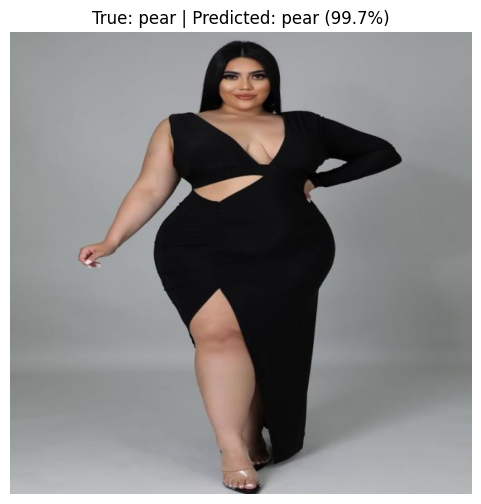

In [10]:

import torch
from torch.utils.data import DataLoader
from torchvision import datasets
import os
from PIL import Image

# Load best model
model_path = "/kaggle/working/best_body_shape_model.pth"
if not os.path.exists(model_path):
    print(f"Model not found: {model_path}")
    !ls -la /kaggle/working
else:
    model.load_state_dict(torch.load(model_path))
    model.eval()
    print("Model loaded successfully")

# ────────────────────────────────────────────────────────────────
# Full Test Set Evaluation
# ────────────────────────────────────────────────────────────────
test_dataset = datasets.ImageFolder(test_dir, transform=val_test_transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

test_correct, test_total = 0, 0
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        outputs = outputs[0] if isinstance(outputs, tuple) else outputs
        _, preds = torch.max(outputs, 1)
        test_correct += (preds == labels).sum().item()
        test_total += labels.size(0)

test_acc = 100.0 * test_correct / test_total if test_total > 0 else 0
print(f"\nFinal Test Accuracy: {test_acc:.2f}%  ({test_correct} / {test_total} correct)")
print(f"Test set size: {len(test_dataset)} images across {len(test_dataset.classes)} classes")

# ────────────────────────────────────────────────────────────────
# Simple Prediction Demo on One Test Image (no Grad-CAM)
# ────────────────────────────────────────────────────────────────
example_class = 'pear'  # change to any class you want to test
example_folder = os.path.join(test_dir, example_class)

if not os.path.exists(example_folder) or len(os.listdir(example_folder)) == 0:
    print(f"No images found in {example_folder}")
    print("Available test classes:", os.listdir(test_dir))
else:
    example_img_name = os.listdir(example_folder)[0]
    example_path = os.path.join(example_folder, example_img_name)

    img = Image.open(example_path).convert('RGB')
    input_tensor = val_test_transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)
        pred_idx = output.argmax(1).item()
        pred = body_shapes[pred_idx]
        conf = torch.softmax(output, dim=1)[0, pred_idx].item()

    print(f"\nExample image (true label: {example_class}):")
    print(f"Predicted → {pred}  ({conf:.1%} confidence)")

    # Optional: show the image itself
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"True: {example_class} | Predicted: {pred} ({conf:.1%})")
    plt.axis('off')
    plt.show()